# Cluster - Upvote dynamics

This notebook will analyze how upvotes differ from cluster to cluster and within the same one.

In [1]:
from src.utils.data_utils import load_reddit_df, load_enhanced_df
import sys, os
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
sys.path.append(os.path.join(os.getcwd(), '..', '..'))
DATA_FOLDER = os.path.join(os.getcwd(), '..', '..', '..', 'data')

df = load_reddit_df(os.path.join(DATA_FOLDER, "reddit_df_merged_jack.pkl"))

df_enh = load_enhanced_df()

In [2]:
df["ups"] = df_enh["ups"]
for i in np.random.choice(df.shape[0], size=100, replace=False):
    if df.iloc[i]["POST_ID"][:6] != df_enh.iloc[i]["POST_ID"]:
        print(df.iloc[i], df_enh.iloc[i])
        raise Exception("There is something wrong in the DFs")
df = df.dropna(subset=['ups'])


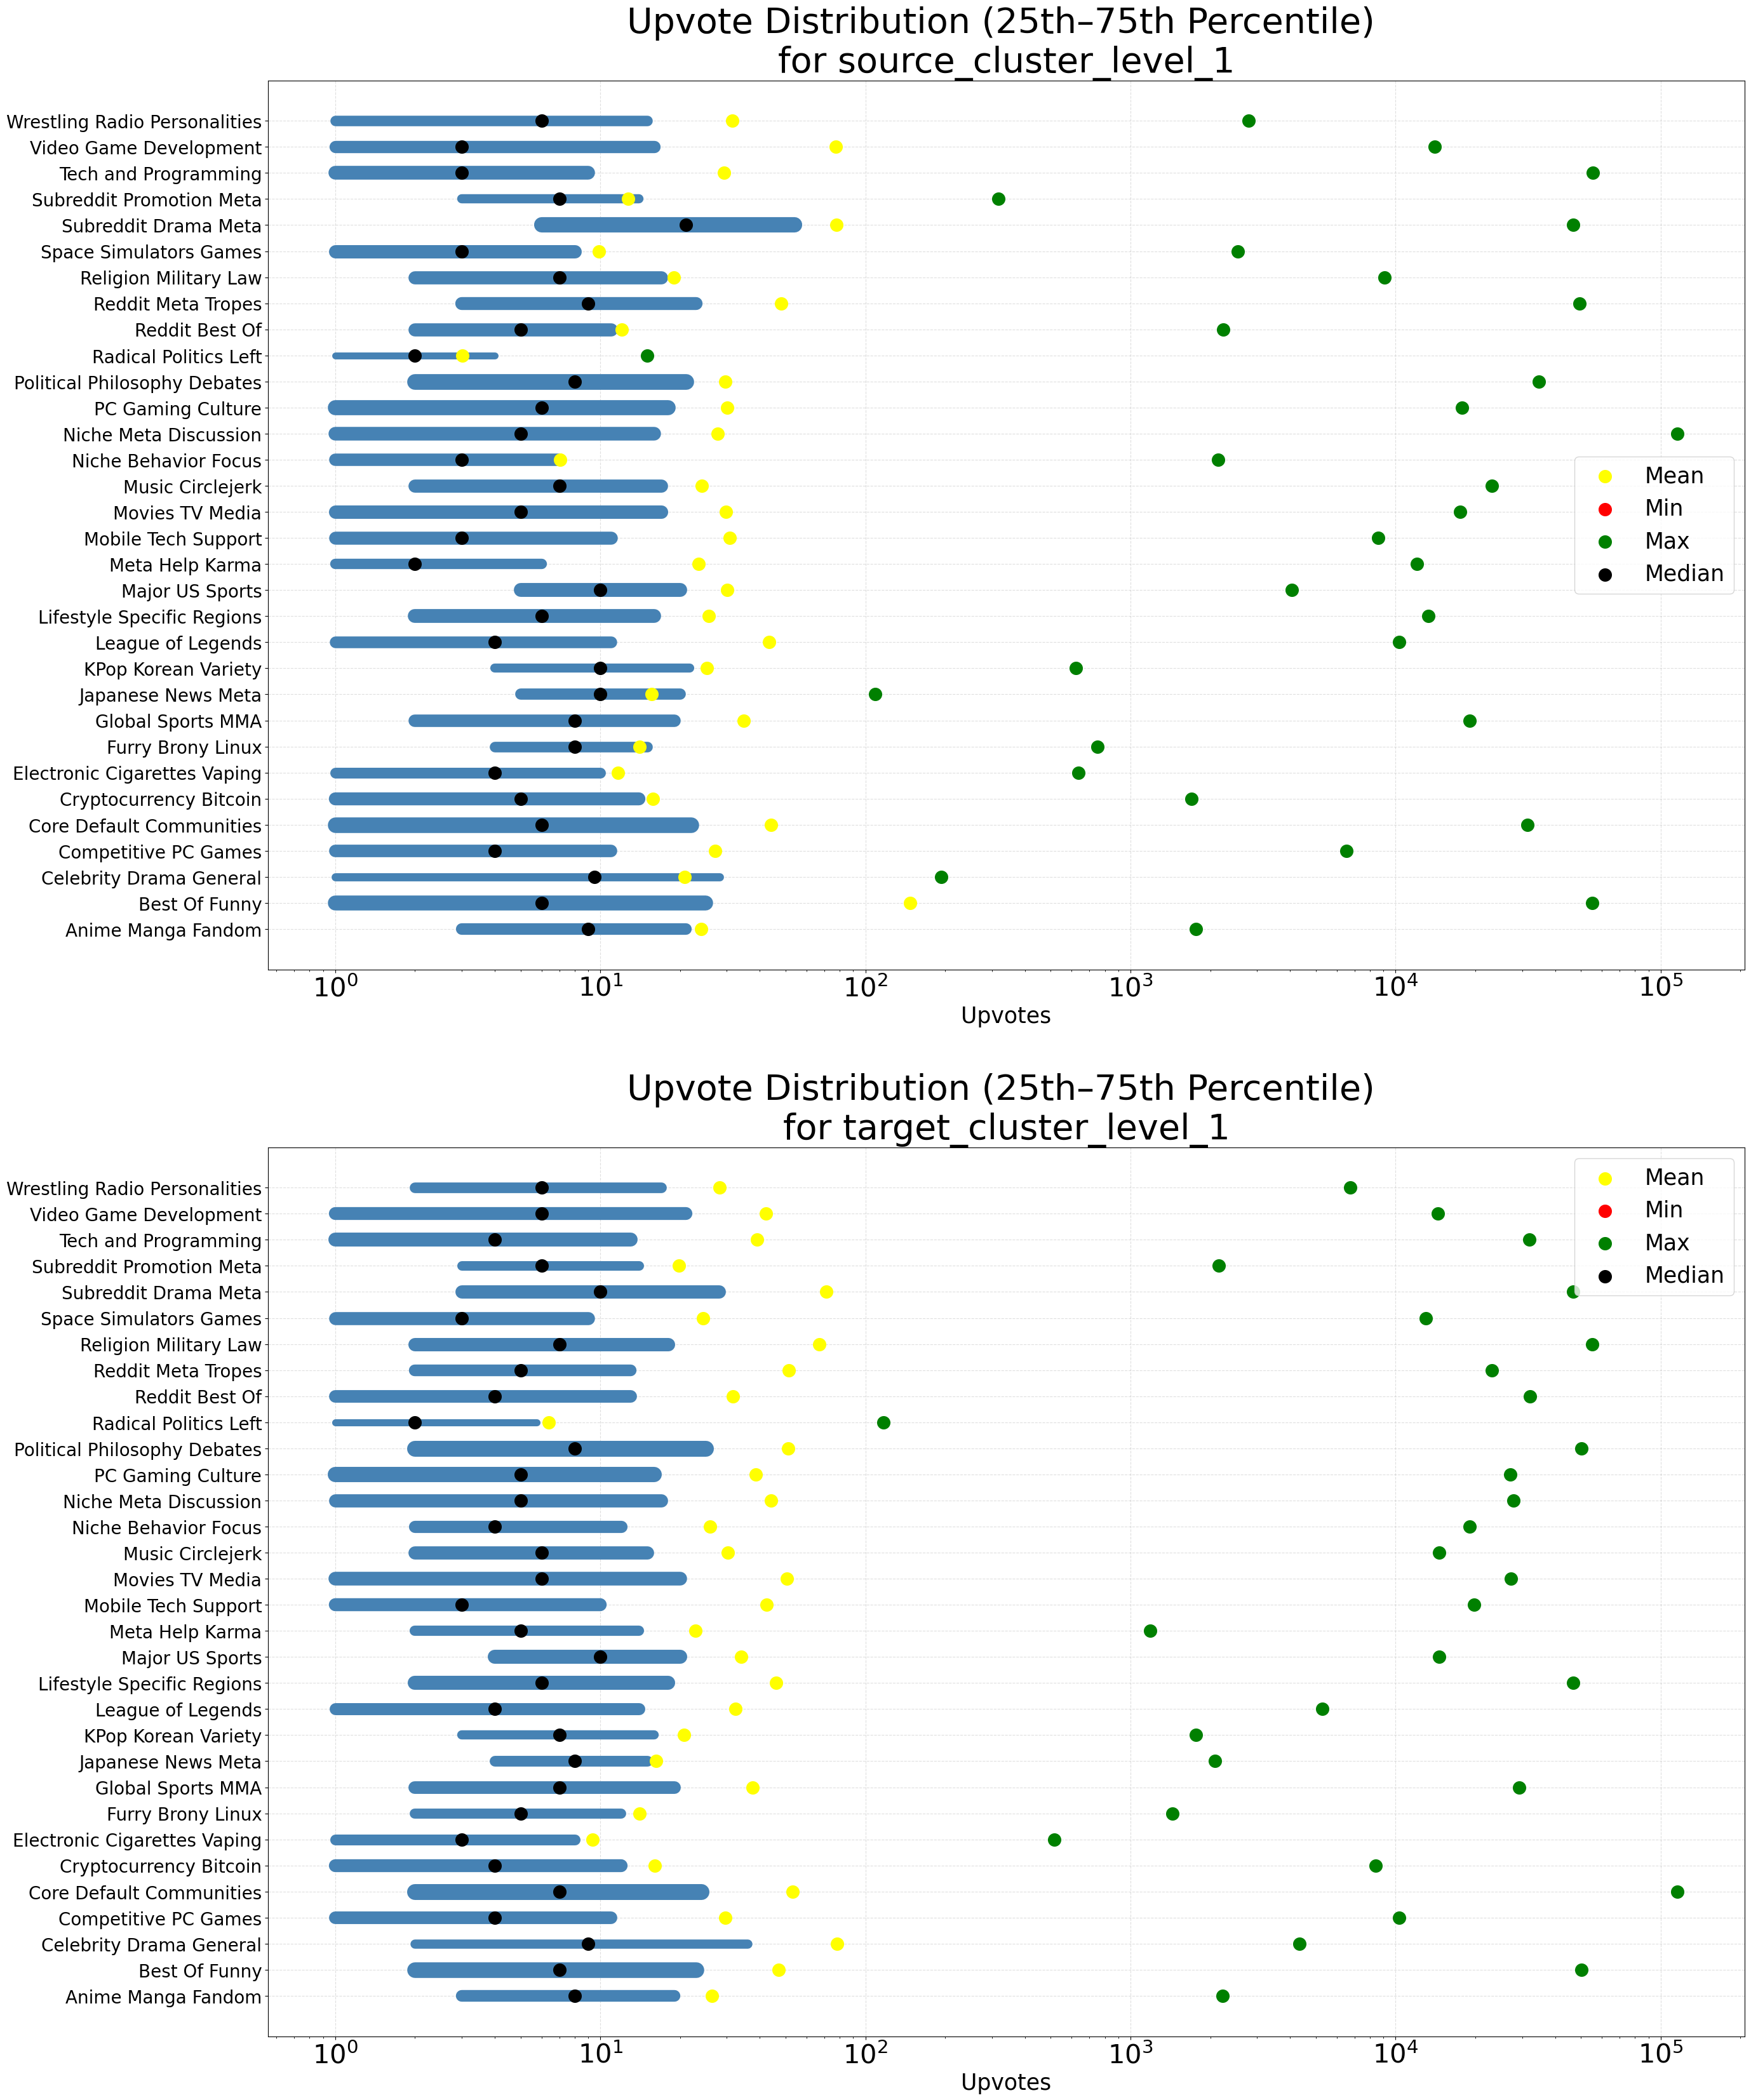

In [32]:
percentiles_src = (
    df.groupby('source_cluster_level_1')['ups']
    .agg(
        minimum='min',
        q25=lambda x: np.percentile(x, 25),
        mean='mean',
        median='median',
        q75=lambda x: np.percentile(x, 75),
        count='count',
        maximum='max'
    )
    .reset_index()
)

percentiles_tgt = (
    df.groupby('target_cluster_level_1')['ups']
    .agg(
        minimum='min',
        q25=lambda x: np.percentile(x, 25),
        mean='mean',
        median='median',
        q75=lambda x: np.percentile(x, 75),
        count='count',
        maximum='max'
    )
    .reset_index()
)

percentiles_lst = [percentiles_src, percentiles_tgt]

_, axes = plt.subplots(2, 1, figsize=(30, 40), squeeze=False)

for i, percentiles in enumerate(percentiles_lst):
    ax = axes[i // 1][i % 1]
    for i, row in enumerate(percentiles.itertuples()):
        ax.plot([row.q25, row.q75], [i, i], color='steelblue', linewidth=(np.log2(row.count)+1), solid_capstyle='round')
        ax.scatter(row.mean, i, color='yellow', zorder=3, s=200, label='Mean' if i == 0 else '')
        ax.scatter(row.minimum, i, color='red', zorder=3, s=200, label='Min' if i == 0 else '')
        ax.scatter(row.maximum, i, color='green', zorder=3, s=200, label='Max' if i == 0 else '')
        ax.scatter(row.median, i, color='black', zorder=3, s=200, label='Median' if i == 0 else '')
    ax.set_yticks(range(len(percentiles)))
    ax.set_yticklabels(percentiles.iloc[: ,0], fontsize=20)
    ax.set_xlabel('Upvotes', fontsize=25)
    ax.tick_params(axis='x', labelsize=30)
    ax.set_title(f'Upvote Distribution (25th–75th Percentile) \nfor {percentiles.columns[0]}', fontsize=40)
    ax.set_xscale('log')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(fontsize=25)
plt.show()

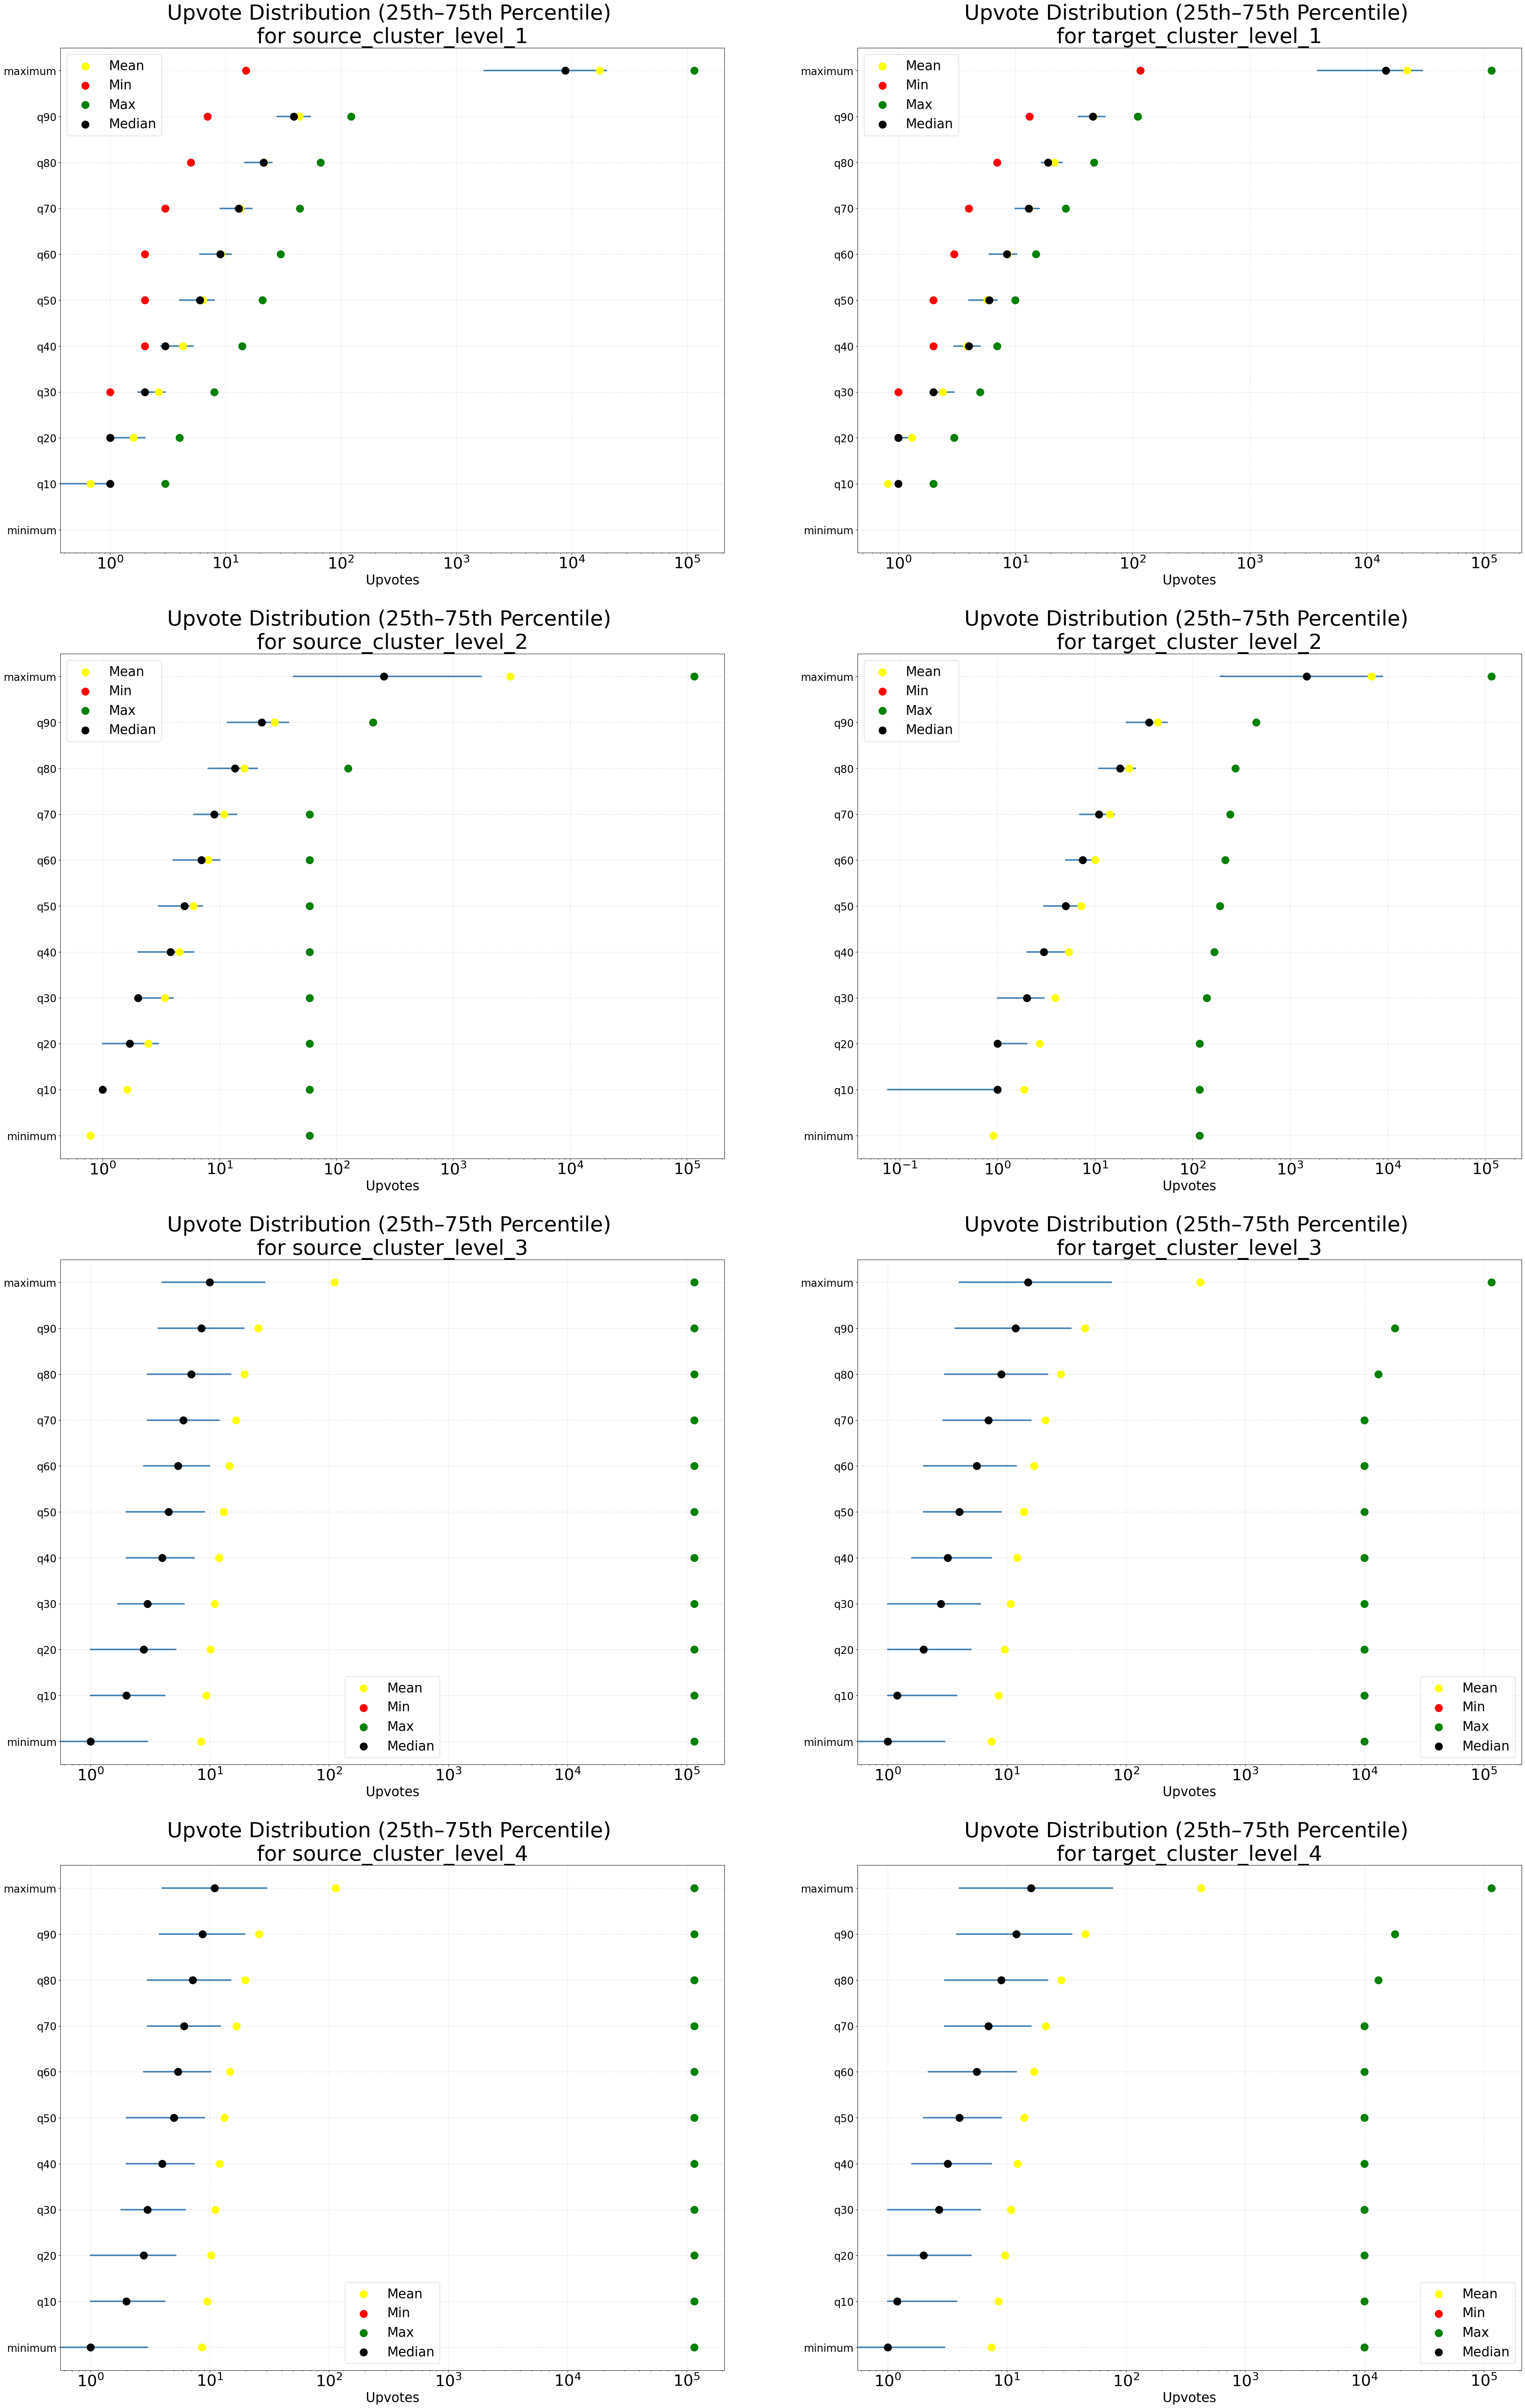

In [28]:
cluster_groups = ["source_cluster_level_1", "target_cluster_level_1", 
                  "source_cluster_level_2", "target_cluster_level_2",
                  "source_cluster_level_3", "target_cluster_level_3",
                  "source_cluster_level_4", "target_cluster_level_4"]
                  

ncols = 2
nrows = 4
_, axes = plt.subplots(nrows, ncols, figsize=(ncols * 25, nrows * 20), squeeze=False)

for i, group in enumerate(cluster_groups):
    ax = axes[i // ncols][i % ncols]
    percentiles = (
        df.groupby(group)['ups']
        .agg(
            minimum='min',
            q10=lambda x: np.percentile(x, 10),
            q20=lambda x: np.percentile(x, 20),
            q30=lambda x: np.percentile(x, 30),
            q40=lambda x: np.percentile(x, 40),
            q50=lambda x: np.percentile(x, 50),
            q60=lambda x: np.percentile(x, 60),
            q70=lambda x: np.percentile(x, 70),
            q80=lambda x: np.percentile(x, 80),
            q90=lambda x: np.percentile(x, 90),
            maximum='max'
        )
        .reset_index()
    )

    cnt = 0
    used_cols = []
    for col_name, col_data in percentiles.items():
        if isinstance(col_data[0], str):
            continue
        used_cols.append(col_name)
        ax.plot([col_data.quantile(0.25), col_data.quantile(0.75)], [cnt, cnt], color='steelblue', linewidth=3, solid_capstyle='round')
        ax.scatter(col_data.mean(), cnt, color='yellow', zorder=3, s=200, label='Mean' if cnt == 0 else '')
        ax.scatter(col_data.min(), cnt, color='red', zorder=3, s=200, label='Min' if cnt == 0 else '')
        ax.scatter(col_data.max(), cnt, color='green', zorder=3, s=200, label='Max' if cnt == 0 else '')
        ax.scatter(col_data.median(), cnt, color='black', zorder=3, s=200, label='Median' if cnt == 0 else '')
        cnt += 1

    ax.set_xlabel('Upvotes', fontsize=25)
    ax.set_yticks(range(len(used_cols)))
    ax.set_yticklabels(used_cols, fontsize=20)
    ax.tick_params(axis='x', labelsize=30)
    ax.set_title(f'Upvote Distribution (25th–75th Percentile) \nfor {group}', fontsize=40)
    ax.set_xscale('log')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(fontsize=25)
plt.show()

In [16]:
percentiles_src

,source_cluster_level_1,minimum,q25,mean,median,q75,count,maximum
0,Anime Manga Fandom,0.0,3.0,23.977324,9.0,21.00,4454,1770.0
1,Best Of Funny,0.0,1.0,147.104895,6.0,25.00,64369,55173.0
2,Celebrity Drama General,0.0,1.0,20.792763,9.5,28.25,304,193.0
3,Competitive PC Games,0.0,1.0,27.158216,4.0,11.00,9506,6522.0
4,Core Default Communities,0.0,1.0,44.156014,6.0,22.00,106997,31374.0
5,Cryptocurrency Bitcoin,0.0,1.0,15.834959,5.0,14.00,13427,1696.0
6,Electronic Cigarettes Vaping,0.0,1.0,11.665685,4.0,10.00,2378,636.0
7,Furry Brony Linux,0.0,4.0,14.051601,8.0,15.00,2093,751.0
8,Global Sports MMA,0.0,2.0,34.751860,8.0,19.00,9007,19080.0
9,Japanese News Meta,0.0,5.0,15.647998,10.0,20.00,3446,109.0
